# prof2 EWMA-CAL — frozen funded sizing

Release **2.2.0** · **$2 million initial capital** · gate **0.15** · **8x target quantities** · **$4 million aggregate margin-proxy cap** · strictly lagged hedge execution.

The forecast and calibration are unchanged. This version scales the same completed-shadow-trade signals, clips quantities to remaining capacity at entry, and charges extra collateral at the prior observed Treasury rate **plus 3%**. Eight times target quantities is not eight times portfolio leverage: the cap often binds.

**Assumptions:** midpoint fills and fractional option equivalents remain hypothetical. Cash interest is collateral income. The margin estimate is a proxy, not a broker guarantee. The later period has already been examined. SPY adjusted total return proxies the S&P 500. The leverage grid does not change the frozen default.

Source: [Market Data](https://www.marketdata.app) historical options; LSEG constituent/underlying inputs; Yahoo Finance via yfinance for the SPY benchmark. Source datasets remain private; the notebook uses derived research results.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config/model.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from ewma_cal.reporting import load_reference, comparison_table, plot_comparison, plot_drawdowns

reference = load_reference(ROOT)
metrics = reference['metrics']
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 130, 'axes.prop_cycle': plt.cycler(color=['#236192', '#d58626', '#657b45'])})
pd.set_option('display.max_columns', 14)
print(json.dumps(json.loads((ROOT / 'config/model.json').read_text()), indent=2))
print(json.dumps(json.loads((ROOT / 'config/sizing.json').read_text()), indent=2))
print('Valuation dates:', reference['manifest']['Start'], 'to', reference['manifest']['End'])

from ewma_cal.figures import export_figures
publication_figures = export_figures(ROOT)
plt.close("all")

{
  "name": "prof2_EWMA_CAL",
  "version": "2.1.0",
  "capital": 2000000,
  "vega_gate": 0.15,
  "hedge_timing": "strictly_lagged"
}
{
  "name": "prof2_EWMA_CAL_size8_cap4m_funded",
  "version": "2.2.0",
  "target_scale": 8.0,
  "margin_cap_usd": 4000000.0,
  "extra_funding_spread": 0.03
}
Valuation dates: 2016-01-04 to 2026-11-10


## Portfolio comparison

Every subperiod starts from the same capital and resets its interest ledger; the full path remains continuous. “Trading only” includes the modeled commissions, hedge execution, borrow, and funding charges. Zero-spread reference fills and full quoted-spread stresses are kept distinct. Raw Sharpe uses a zero benchmark; **Treasury-excess Sharpe** removes collateral-rate accrual.

Trading P&L here includes the **additional collateral-funding charge**. The forecast itself remains the original scaled shadow-payoff prediction before that extra funding stress.

In [2]:
for period in ['Full', 'Development', 'OOS']:
    print(period)
    display(comparison_table(reference, period).style.format({
        'TotalReturn': '{:.2%}', 'CAGR': '{:.2%}', 'MaxDrawdown': '{:.2%}',
        'Sharpe': '{:.3f}', 'TreasuryExcessSharpe': '{:.3f}', 'Calmar': '{:.3f}',
        'InformationRatioSP500': '{:.3f}'}, na_rep='—'))

Full


,TotalReturn,CAGR,Sharpe,TreasuryExcessSharpe,MaxDrawdown,Calmar,InformationRatioSP500
Portfolio,,,,,,,
Trading only,24.63%,2.05%,0.625,-0.067,-4.96%,0.414,-0.747
With cash interest,58.95%,4.36%,1.377,0.641,-4.16%,1.048,-0.621
S&P 500 (SPY total return),343.60%,14.72%,0.865,0.735,-33.72%,0.437,—
Treasury collateral,28.48%,2.34%,13.651,—,0.00%,—,-0.735


Development


,TotalReturn,CAGR,Sharpe,TreasuryExcessSharpe,MaxDrawdown,Calmar,InformationRatioSP500
Portfolio,,,,,,,
Trading only,26.69%,6.10%,1.368,1.118,-3.94%,1.549,-0.585
With cash interest,31.15%,7.02%,1.625,1.366,-3.80%,1.847,-0.544
S&P 500 (SPY total return),89.40%,17.34%,0.873,0.820,-33.72%,0.514,—
Treasury collateral,4.45%,1.10%,13.263,—,0.00%,—,-0.820


OOS


,TotalReturn,CAGR,Sharpe,TreasuryExcessSharpe,MaxDrawdown,Calmar,InformationRatioSP500
Portfolio,,,,,,,
Trading only,-2.05%,-0.43%,-0.094,-1.164,-6.23%,-0.069,-0.712
With cash interest,19.64%,3.77%,1.038,-0.077,-4.98%,0.756,-0.478
S&P 500 (SPY total return),67.25%,11.18%,0.700,0.466,-24.50%,0.457,—
Treasury collateral,21.66%,4.12%,21.283,—,0.00%,—,-0.466


## Implied versus realized correlation

The implied proxy uses DIA and all 30 point-in-time constituent straddle IVs. Realized correlation uses the same constituent weights and uncentered return second moments over the five-session hold (t+2 through t+6). Monthly averages are shown by realization month; the average gap equally weights paired daily observations. Overlapping horizons are descriptive, not independent observations.

**Tenor distinction:** implied correlation reflects the selected option expiry, generally around 30 days; realized correlation covers five sessions. This chart is not a matched-tenor correlation-risk-premium estimate or the calibrated entry signal. No clipping is applied. Sources: [Market Data](https://www.marketdata.app) and LSEG.

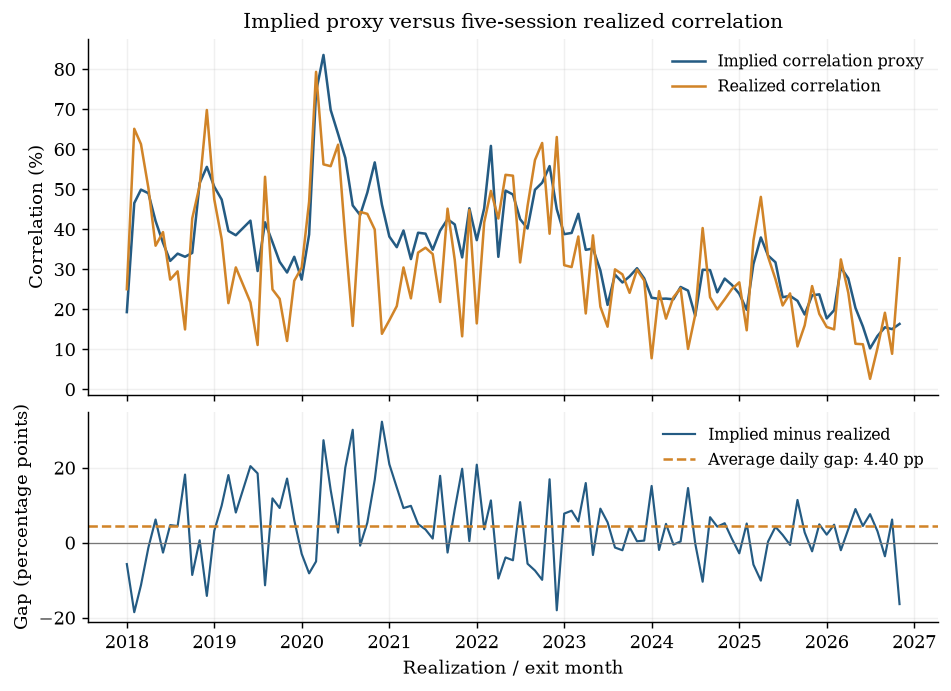

In [3]:
display(publication_figures["implied_realized_correlation"])

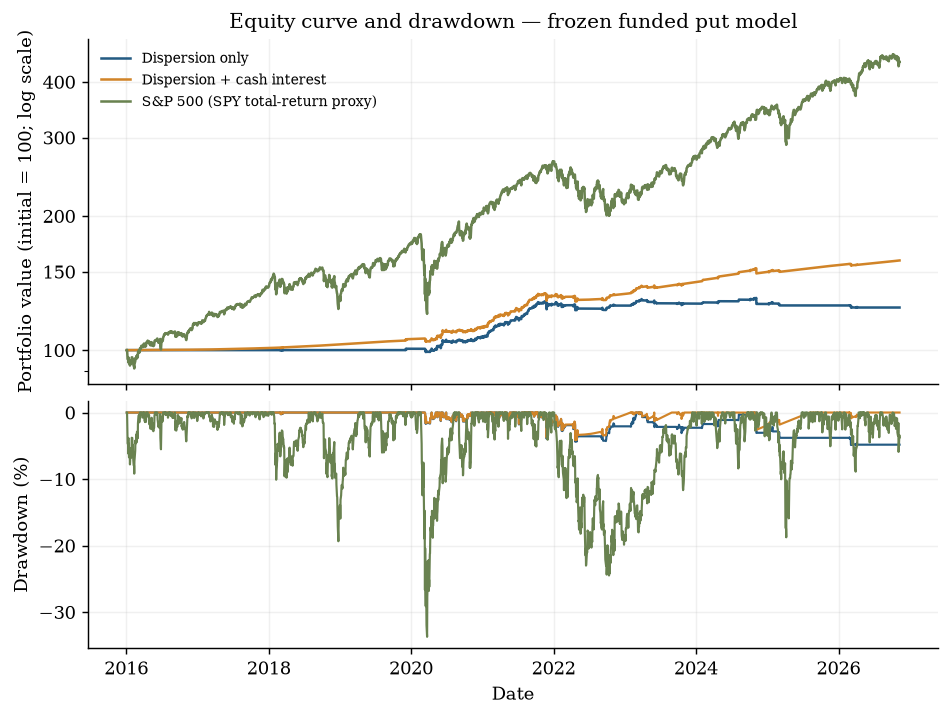

In [4]:
display(publication_figures["equity_drawdown"])

## Cash and trading attribution

Collateral earns the prior observed one-month Treasury yield on ACT/365.25. Only settled trade P&L changes the remunerated balance. Interest is reinvested but never resizes the trading overlay. The Treasury-only portfolio shows what collateral would earn without trading.

,Trading P&L ($),Cash interest ($),Combined gain ($),Treasury-only gain ($),Trades
Period,,,,,
Full,"492,650.12","686,375.84","1,179,025.96","569,654.49",115.00
Development,"533,731.18","89,312.58","623,043.76","89,022.87",75.00
OOS,"-41,081.06","433,933.10","392,852.04","433,163.95",40.00


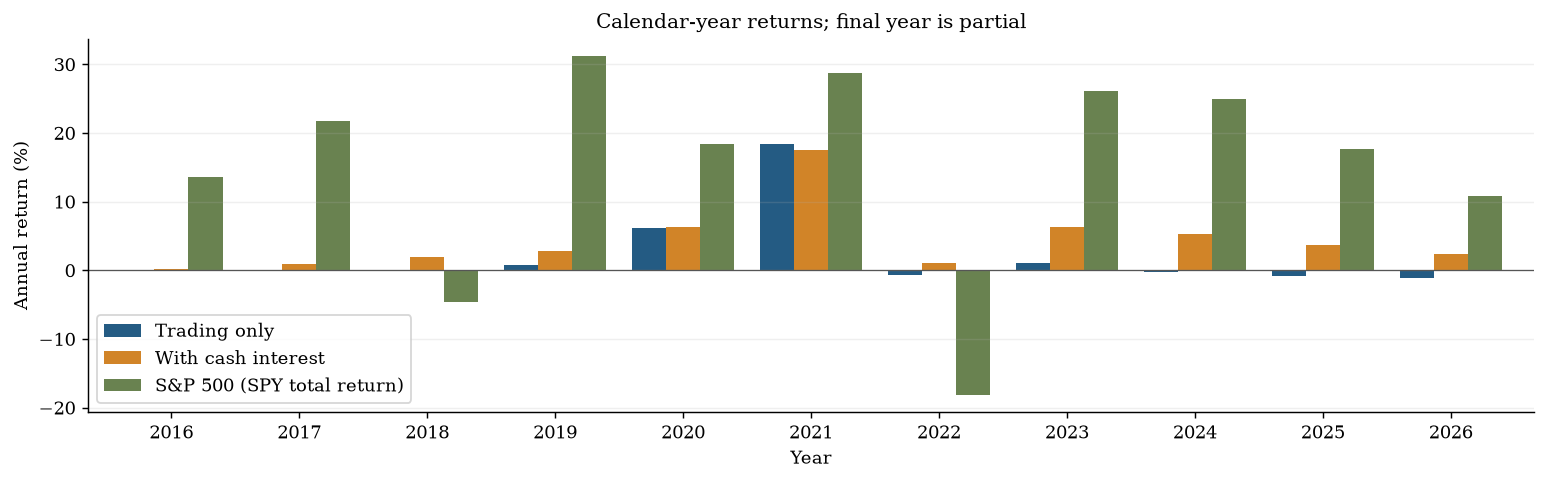

In [5]:
primary = metrics[metrics.Primary]
rows = []
for period in ['Full', 'Development', 'OOS']:
    table = primary[primary.Period == period].set_index('Portfolio')
    trading = table.loc['Trading only', 'NetPnL']
    cash = table.loc['With cash interest', 'CashInterest']
    rows.append({'Period': period, 'Trading P&L ($)': trading, 'Cash interest ($)': cash,
                 'Combined gain ($)': trading + cash,
                 'Treasury-only gain ($)': table.loc['Treasury collateral', 'NetPnL'],
                 'Trades': int(table.loc['Trading only', 'Trades'])})
display(pd.DataFrame(rows).set_index('Period').style.format('{:,.2f}'))

annual = reference['annual'].rename(columns={'TradingEquity': 'Trading only',
                    'CashEquity': 'With cash interest', 'SP500Equity': 'S&P 500 (SPY total return)'})
ax = (100 * annual).plot.bar(figsize=(12, 3.8), width=.8)
ax.set(ylabel='Annual return (%)', title='Calendar-year returns; final year is partial')
ax.axhline(0, color='#555555', linewidth=.7)
ax.grid(axis='y', alpha=.2)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## Payoff forecasts and trade concentration

Forecast errors are evaluated on **entered positions**, with outcomes assigned by entry date. MSE is in dollars squared; RMSE/MAE are dollars. **ASE** is `mean(((predicted - realized) / forecast_risk)**2)`, so it measures error in forecast-risk units. These are payoff predictions, not physical covariance forecast errors. The target remains the original post-quote shadow payoff while realized P&L here uses lagged execution.

In [6]:
display(reference['forecasts'].set_index(['Period', 'Book']).style.format({
    'MSE': '{:,.1f}', 'RMSE': '{:,.1f}', 'MAE': '{:,.1f}', 'ASE': '{:.3f}',
    'PearsonIC': '{:.3f}', 'SpearmanIC': '{:.3f}', 'Bias': '{:,.1f}'}))
trades = reference['trades'].copy()
assert (trades.LastTrainingExit < trades.SignalDate).all()
assert (trades.SignalDate < trades.EntryDate).all()
assert (trades.EntryDate <= trades.ExitDate).all()
rows = []
for book, f in trades.groupby('Book'):
    pnl = f.NetUSD
    rows.append({'Book': book, 'Trades': len(f), 'Win rate': (pnl > 0).mean(),
                 'Net P&L ($)': pnl.sum(), 'Median ($)': pnl.median(),
                 'Best ($)': pnl.max(), 'Worst ($)': pnl.min(),
                 'Profit factor': pnl[pnl > 0].sum() / -pnl[pnl < 0].sum(),
                 'Top-5 share of positive P&L': pnl.nlargest(5).sum() / pnl[pnl > 0].sum()})
display(pd.DataFrame(rows).set_index('Book').style.format({
    'Win rate': '{:.1%}', 'Net P&L ($)': '{:,.0f}', 'Median ($)': '{:,.0f}',
    'Best ($)': '{:,.0f}', 'Worst ($)': '{:,.0f}', 'Profit factor': '{:.2f}',
    'Top-5 share of positive P&L': '{:.1%}'}))
print('Entered positions with missing daily marks:', int((trades.MissingDaily > 0).sum()))
print('All recorded calibration exits precede their signal dates.')

,Trades,Win rate,Net P&L ($),Median ($),Best ($),Worst ($),Profit factor,Top-5 share of positive P&L
Book,,,,,,,,
variance,73,64.4%,"404,307","6,223","49,768","-70,921",2.05,23.9%
vega,42,57.1%,"88,343",793,"35,267","-31,918",1.67,61.3%


Entered positions with missing daily marks: 0
All recorded calibration exits precede their signal dates.


## Predicted versus realized payoff, by sleeve

Each point is an entered trade. The dashed line denotes perfect prediction; both sleeves use common axis limits, with dollar values in thousands. Predictions are the calibrated, scaled shadow-payoff forecasts before the additional collateral-funding stress. Realizations include that funding charge. Colors distinguish Development and OOS. The OOS window has already been examined; this label does not imply independent validation.

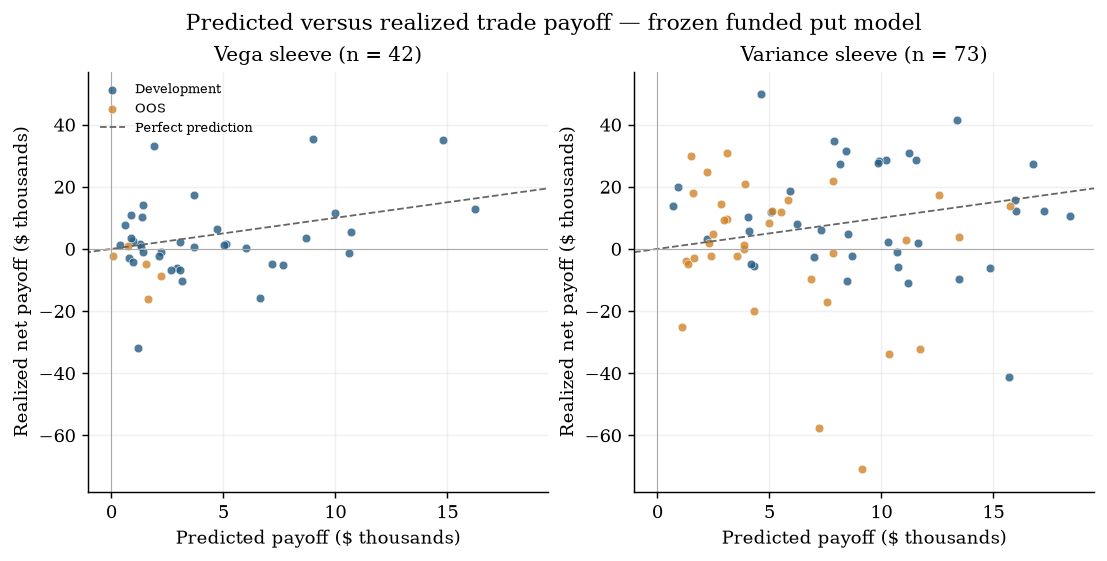

In [7]:
display(publication_figures["predicted_realized_payoff"])

## Hedge timing and option-spread sensitivity

The same signals and original sizes are replayed under both hedge timings. A spread fraction of 1 charges the full observed entry-plus-exit half-spread; 0 is the midpoint reference. All other fees remain. Signals and shadow training labels are **not refitted** to the execution stress.

,,,Trades,NetPnL,CAGR,Sharpe,MaxDrawdown
Period,Hedge,SpreadFraction,,,,,
Full,strictly_lagged,0.000000,115.000000,"492,650",2.05%,0.625,-4.96%
Development,strictly_lagged,0.000000,75.000000,"533,731",6.10%,1.368,-3.94%
OOS,strictly_lagged,0.000000,40.000000,"-41,081",-0.43%,-0.094,-6.23%
Full,strictly_lagged,0.250000,115.000000,"129,897",0.58%,0.168,-8.77%
Development,strictly_lagged,0.250000,75.000000,"283,704",3.38%,0.681,-4.57%
OOS,strictly_lagged,0.250000,40.000000,"-153,807",-1.64%,-0.378,-8.84%
Full,strictly_lagged,0.500000,115.000000,"-232,857",-1.13%,-0.211,-15.73%
Development,strictly_lagged,0.500000,75.000000,"33,677",0.42%,0.099,-10.41%
OOS,strictly_lagged,0.500000,40.000000,"-266,534",-2.91%,-0.596,-14.30%


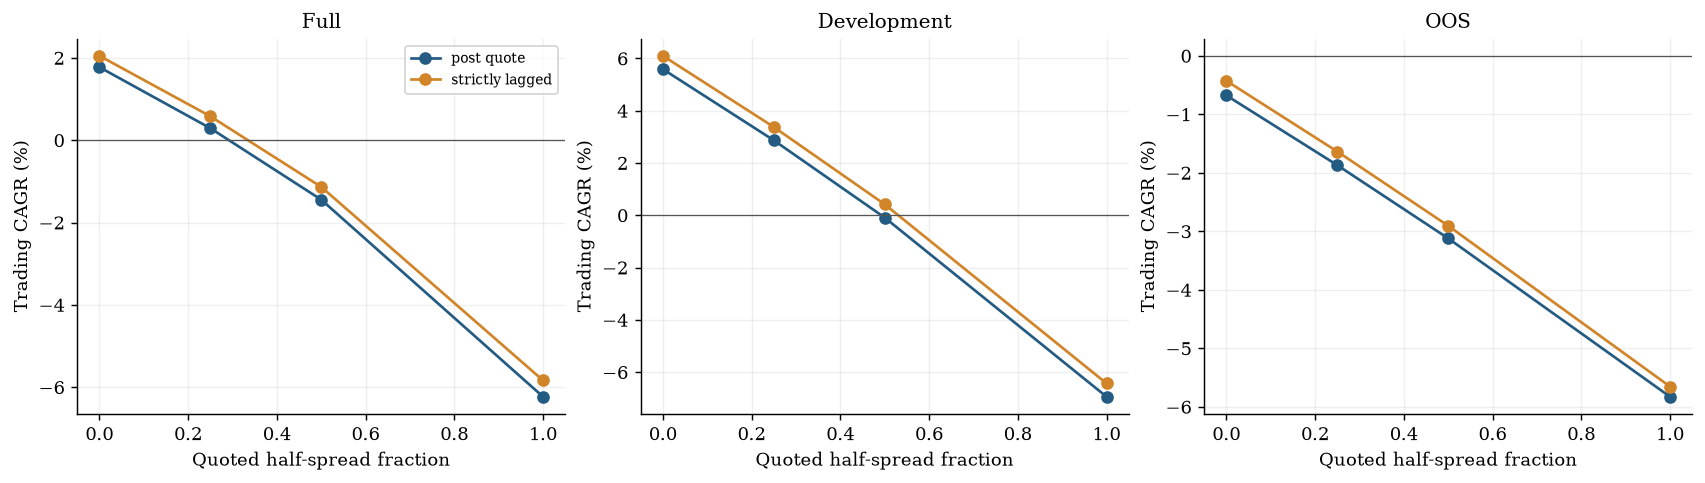

In [8]:
stress = metrics[metrics.Portfolio == 'Trading only']
display(stress.set_index(['Period', 'Hedge', 'SpreadFraction'])[
    ['Trades', 'NetPnL', 'CAGR', 'Sharpe', 'MaxDrawdown']].style.format({
    'NetPnL': '{:,.0f}', 'CAGR': '{:.2%}', 'Sharpe': '{:.3f}', 'MaxDrawdown': '{:.2%}'}))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout='constrained')
for ax, period in zip(axes, ['Full', 'Development', 'OOS']):
    for timing, f in stress[stress.Period == period].groupby('Hedge'):
        ax.plot(f.SpreadFraction, 100 * f.CAGR, marker='o', label=timing.replace('_', ' '))
    ax.axhline(0, color='#555555', linewidth=.7)
    ax.set(title=period, xlabel='Quoted half-spread fraction', ylabel='Trading CAGR (%)')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.show()

## Verification and provenance

The funded model reproduced the preceding saved sizing review for all three periods and both cash treatments. Position P&L, extra funding allocations, and the cash ledger reconcile. Capacity is clipped only at entry, with unchanged signals and matured calibration labels. Unit tests independently guard the cap, proportional scaling, prior-rate financing, invalid configurations, missing marks, cash settlement and benchmark alignment.

The core remains the preserved release 2.1.0. Frozen configuration and core/sizing checksums were recorded before the leverage grid. The 8x funded model remains the default regardless of which grid row has the strongest historical metric.

In [9]:
verification = json.loads((ROOT / 'reports/reference/verification.json').read_text())
print('Funded review reproduced:', verification['OriginalFrozenReviewReproduced'])
print('Funding fully allocated:', verification['FundingFullyAllocated'])
print('Frozen core release:', verification['ParentRelease'])
print('Benchmark source:', json.loads((ROOT / 'reports/reference/benchmark_source.json').read_text())['Provider'])

from ewma_cal.leverage import check_freeze
lock = check_freeze(ROOT)
print('Frozen model:', lock['Name'])

Funded review reproduced: True
Funding fully allocated: True
Frozen core release: 233cbd2
Benchmark source: Yahoo Finance via yfinance
Frozen model: prof2_EWMA_CAL_size8_cap4m_funded


## Fixed-cap leverage comparison

Only the target quantity multiple changes. The $4m margin-proxy cap, additional funding charge, signals and hedge convention stay fixed. **The default remains 8x.** All rows are retrospective research comparisons; target size is not a fixed portfolio leverage ratio. Higher exposure can change the number of admitted entries.

The overview shows both full-period cash treatments and the previously examined later-window trading result. Dollar payoff MSE scales with exposure; normalized ASE and sleeve-level errors are available in the forecast table below.

,FullTradingCAGR,FullCashCAGR,TradingSharpe,CashTreasuryExcessSharpe,TradingMaxDD,LaterTradingCAGR,DevelopmentTradingCAGR,Trades,MeanActualScale,ClippedFraction,WithinDepthFraction
Target,,,,,,,,,,,
0.500000,0.16%,2.49%,0.578,0.600,-0.49%,-0.02%,0.45%,116,0.50,0.0%,81.0%
1.000000,0.35%,2.68%,0.650,0.672,-0.93%,-0.01%,0.95%,116,1.00,0.0%,69.8%
2.000000,0.71%,3.04%,0.694,0.715,-1.76%,0.02%,1.93%,116,2.00,0.0%,38.8%
3.000000,1.06%,3.38%,0.712,0.732,-2.51%,0.04%,2.88%,116,3.00,0.0%,26.7%
4.000000,1.36%,3.68%,0.703,0.723,-3.28%,-0.01%,3.75%,116,4.00,0.0%,19.8%
6.000000,1.72%,4.04%,0.625,0.645,-4.72%,-0.38%,5.13%,116,5.93,6.0%,10.3%
8.000000,2.05%,4.36%,0.625,0.641,-4.96%,-0.43%,6.10%,115,7.53,42.6%,6.1%
10.000000,2.11%,4.42%,0.607,0.623,-5.02%,-0.39%,6.22%,114,8.40,65.8%,5.3%
12.000000,2.08%,4.39%,0.572,0.587,-5.10%,-0.41%,6.16%,114,9.03,70.2%,5.3%


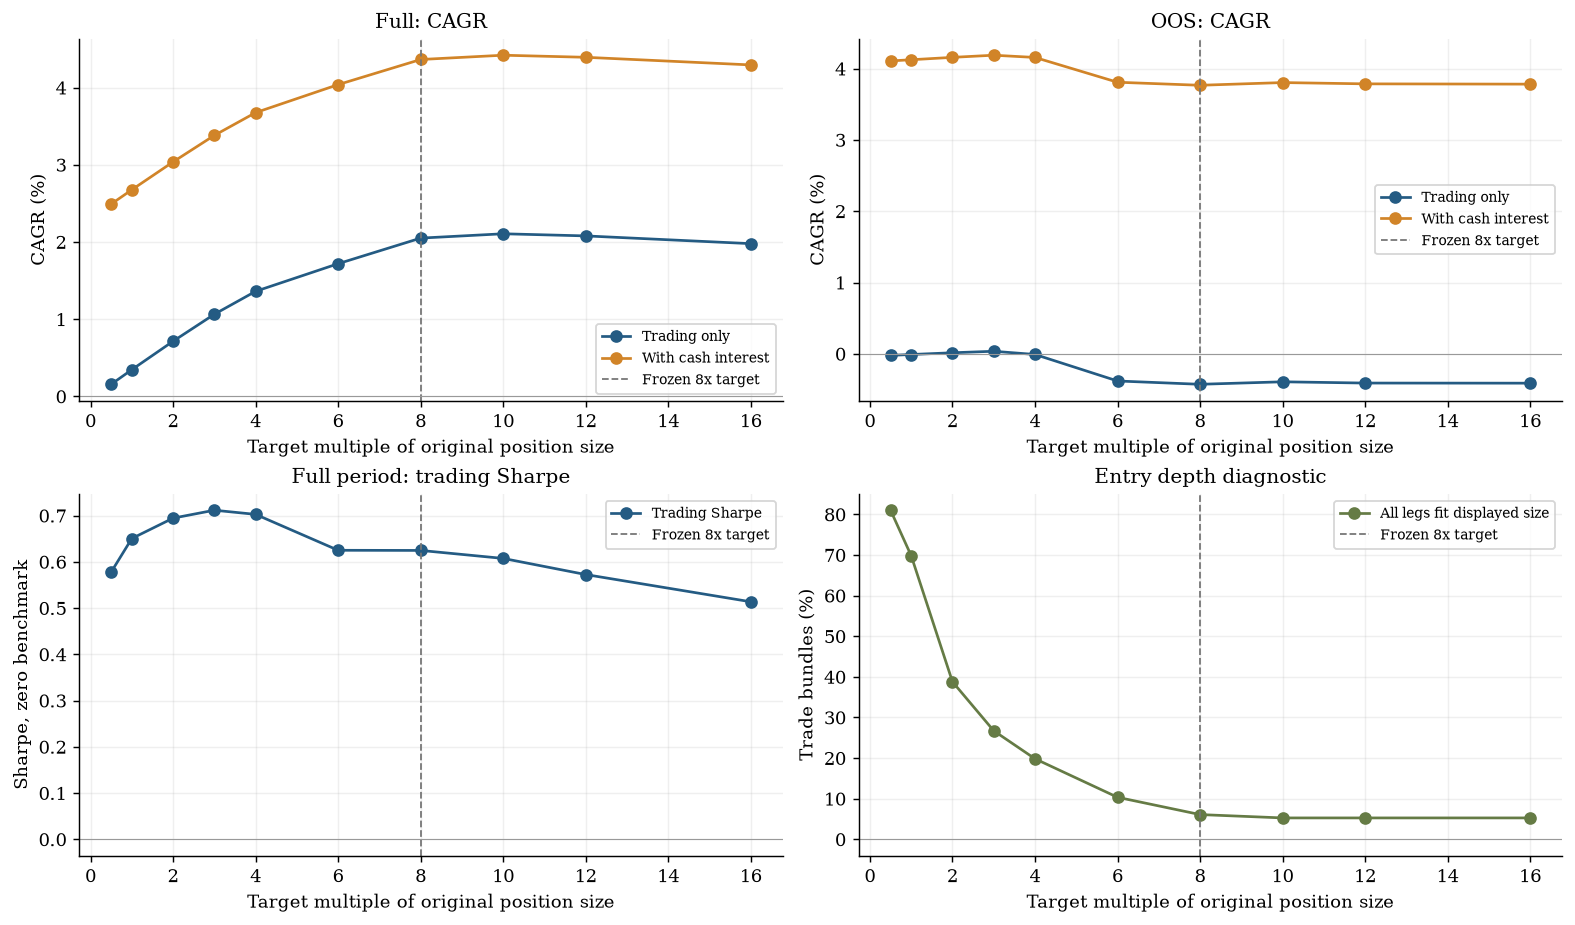

,N,MSE,RMSE,MAE,ASE,PearsonIC
TargetScale,,,,,,
0.500000,116,"1,587,160","1,260",873,2.801,0.048
1.000000,116,"6,348,638","2,520","1,747",2.801,0.066
2.000000,116,"25,394,552","5,039","3,493",2.801,0.077
3.000000,116,"57,095,032","7,556","5,237",2.801,0.082
4.000000,116,"102,379,291","10,118","6,997",2.817,0.082
6.000000,116,"228,576,989","15,119","10,388",2.836,0.077
8.000000,115,"342,107,042","18,496","12,943",2.853,0.088
10.000000,114,"377,974,179","19,442","13,973",2.529,0.090
12.000000,114,"402,804,544","20,070","14,607",2.533,0.092


Frozen 8x configuration remains unchanged after the leverage comparison.


In [10]:
from ewma_cal.leverage import plot_leverage
leverage = pd.read_csv(ROOT / 'reports/leverage/leverage_metrics.csv')
overview = pd.read_csv(ROOT / 'reports/leverage/overview.csv').set_index('Target')
display(overview.style.format({'FullTradingCAGR':'{:.2%}', 'FullCashCAGR':'{:.2%}',
    'TradingSharpe':'{:.3f}', 'CashTreasuryExcessSharpe':'{:.3f}', 'TradingMaxDD':'{:.2%}',
    'LaterTradingCAGR':'{:.2%}', 'DevelopmentTradingCAGR':'{:.2%}', 'MeanActualScale':'{:.2f}',
    'ClippedFraction':'{:.1%}', 'WithinDepthFraction':'{:.1%}'}))
fig = plot_leverage(leverage)
plt.show()
forecast_grid = pd.read_csv(ROOT / 'reports/leverage/leverage_forecasts.csv')
display(forecast_grid[(forecast_grid.Period == 'Full') & (forecast_grid.Book == 'both')]
        .set_index('TargetScale')[['N','MSE','RMSE','MAE','ASE','PearsonIC']]
        .style.format({'MSE':'{:,.0f}','RMSE':'{:,.0f}','MAE':'{:,.0f}',
                       'ASE':'{:.3f}','PearsonIC':'{:.3f}'}))
check_freeze(ROOT)
print('Frozen 8x configuration remains unchanged after the leverage comparison.')